<a href="https://colab.research.google.com/github/athfizh/PemMes26_05_Hafizh/blob/main/JS09/JS09-05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

# **Approximate Nearest Neighbors (ANN) - Lab 5**

---

> Lab 5 mengukur performa ANN dengan **Recall**. Recall menunjukkan berapa banyak tetangga yang benar-benar sama dengan hasil exact NN. Membandingkan **ANNOY**, **FAISS IVF**, dan **HNSW** pada dataset 100.000 vektor 128D dengan 1.000 query, lalu plot recall vs waktu query.

> Cara baca grafiknya: sumbu X adalah **recall** (makin ke kanan makin akurat), sumbu Y adalah **query time** dalam ms/query (makin ke atas makin cepat karena sumbu Y dibalik). Posisi ideal ada di **kanan atas**: recall tinggi dan waktu kecil. Posisi kanan bawah berarti akurat tapi lambat, sedangkan kiri atas berarti cepat tapi kurang akurat.

---

# **Langkah 0 - Install Library**

---

In [1]:
# Install library ANN yang dipakai.
# memakai faiss-gpu, kalau wheel-nya tidak cocok dengan
# versi Python Colab, otomatis fallback ke faiss-cpu.
!pip install -q annoy hnswlib
!pip install -q faiss-gpu

import subprocess, sys

try:
    import faiss
    print("FAISS terpasang:", faiss.__version__)
    print("GPU support:", hasattr(faiss, "StandardGpuResources"))
except Exception as e:
    print("faiss-gpu tidak bisa dipakai di runtime ini:", e)
    print("Fallback: memasang faiss-cpu supaya notebook tetap jalan...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "faiss-cpu"], check=False)
    import faiss
    print("FAISS CPU terpasang:", faiss.__version__)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
FAISS terpasang: 1.15.1
GPU support: True


> Cell ini memasang <code>annoy</code>, <code>hnswlib</code>, dan <code>faiss-gpu</code> sekaligus. Bagian <code>try/except</code> hanya jaring pengaman: kalau <code>faiss-gpu</code> tidak tersedia untuk versi Python Colab, otomatis dipasang <code>faiss-cpu</code> supaya cell import di bawah tidak error.

---

# **Langkah 1 - Import Library**

---

In [2]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

> <code>faiss</code> dipakai untuk ground truth dan index IVF, <code>AnnoyIndex</code> untuk ANNOY, <code>hnswlib</code> untuk HNSW, dan <code>matplotlib</code> untuk plot trade-off.

---

# **Langkah 2 - Dataset Random 100K x 128D**

---

In [3]:
# -------------------------------
# Dataset random
# -------------------------------
d = 128        # dimensi
nb = 100000    # jumlah database vector
nq = 1000      # jumlah query

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

print("Database:", xb.shape)
print("Query   :", xq.shape)

Database: (100000, 128)
Query   : (1000, 128)


> 128 dimensi dipilih karena mirip dengan ukuran embedding yang umum dipakai di retrieval teks/gambar. 100.000 vektor masih cukup besar untuk melihat perbedaan performa, tapi masih nyaman dijalankan di Colab. <code>float32</code> wajib untuk FAISS dan hnswlib.

---

# **Langkah 3 - Ground Truth dengan FAISS Brute Force**

---

In [4]:
# -------------------------------
# Ground truth dengan FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

print("Shape ground truth:", gt_idx.shape)
print("Contoh ground truth query 0:", gt_idx[0])

Shape ground truth: (1000, 10)
Contoh ground truth query 0: [19523 72727 34414 30313 31191  3890  7176 86931  4934 20772]


> Ground truth adalah hasil **exact NN** untuk semua 1.000 query. FAISS FlatL2 menghitung jarak ke seluruh 100.000 vektor, jadi hasilnya dijadikan patokan kebenaran. Nanti hasil ANN dibandingkan dengan <code>gt_idx</code> ini untuk menghitung recall.

---

# **Langkah 4 - Fungsi Recall**

---

In [5]:
# -------------------------------
# Fungsi recall
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

> Fungsi ini membandingkan top-k hasil prediksi dengan top-k ground truth. <code>set(...) & set(...)</code> mengambil irisan, lalu jumlah irisan dibagi <code>(jumlah query x k)</code>. Nilai 1.0 berarti semua tetangga benar, nilai 0.5 berarti setengahnya meleset.

---

# **Langkah 5 - Benchmark ANNOY**

---

In [6]:
# -------------------------------
# Benchmark Annoy
# -------------------------------
def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)

    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

> <code>search_k</code> adalah knob utama ANNOY: semakin besar nilainya, semakin banyak kandidat yang diperiksa, sehingga recall naik tapi waktu query juga naik. Di sini saya akan mencoba <code>search_k</code> 200, 500, 1000, dan 2000.

---

# **Langkah 6 - Benchmark FAISS IVF**

---

In [7]:
# -------------------------------
# Benchmark FAISS IVF
# -------------------------------
def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)

    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

> <code>nprobe</code> menentukan berapa banyak klaster IVF yang diperiksa saat query. <code>nprobe=1</code> paling cepat tapi recall rendah; <code>nprobe</code> besar mendekati exact tapi lebih lambat. Saya mencoba 1, 5, 10, dan 20.

---

# **Langkah 7 - Benchmark HNSW**

---

In [8]:
# -------------------------------
# Benchmark HNSW
# -------------------------------
def run_hnsw(xb, xq, ef=100, M=16, k=10):
    num_elements = xb.shape[0]
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
    p.add_items(xb)
    p.set_ef(ef)

    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

> <code>ef</code> adalah ukuran kandidat saat query. Semakin besar <code>ef</code>, semakin akurat tapi semakin lambat. Saya akan mencoba 50, 100, 200, dan 400. Parameter <code>M=16</code> dan <code>ef_construction=200</code> dibuat tetap supaya perbandingan fokus ke <code>ef</code>.

---

# **Langkah 8 - Jalankan Benchmark**

---

In [9]:
# -------------------------------
# Jalankan benchmark dengan beberapa parameter
# -------------------------------
results = {"Annoy": [], "Faiss": [], "HNSW": []}

# Annoy
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
    results["Annoy"].append((rec, t))

# FAISS
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
    results["Faiss"].append((rec, t))

# HNSW
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(xb, xq, ef=ef)
    results["HNSW"].append((rec, t))

# Tampilkan hasil dalam bentuk tabel
for label in results:
    print("\n===", label, "===")
    for rec, t in results[label]:
        print(f"recall={rec:.4f} | {t:.4f} ms/query")


=== Annoy ===
recall=0.0221 | 0.2064 ms/query
recall=0.0453 | 0.1393 ms/query
recall=0.0772 | 0.3281 ms/query
recall=0.1331 | 0.4052 ms/query

=== Faiss ===
recall=0.0554 | 0.0418 ms/query
recall=0.1912 | 0.1870 ms/query
recall=0.3182 | 0.3759 ms/query
recall=0.5009 | 0.7615 ms/query

=== HNSW ===
recall=0.2995 | 0.1691 ms/query
recall=0.4419 | 0.2903 ms/query
recall=0.6104 | 0.5270 ms/query
recall=0.7705 | 0.9817 ms/query


> Setiap baris di tabel adalah satu konfigurasi parameter. Perhatikan hubungannya: saat parameter pencarian dinaikkan, recall biasanya naik dan waktu query juga naik. Kalau ada yang aneh (misalnya recall turun saat parameter naik), bisa jadi karena faktor randomness atau karena datasetnya sudah sangat mudah.

---

# **Langkah 9 - Visualisasi Trade-off**

---

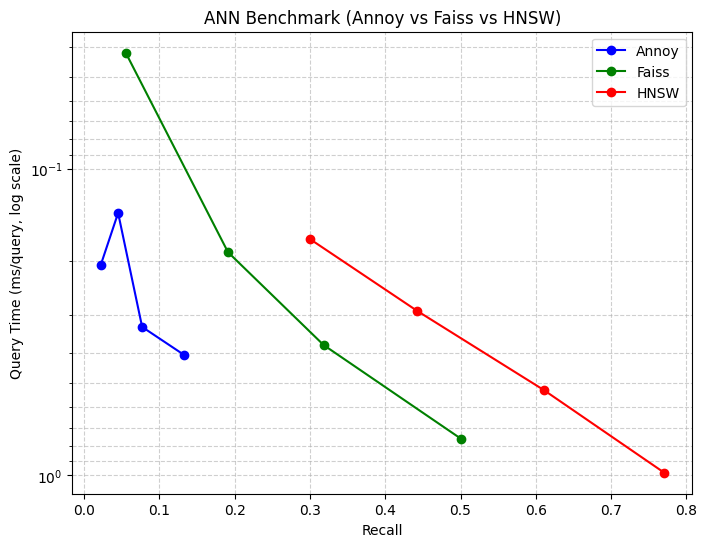

In [10]:
# -------------------------------
# Visualisasi trade-off
# -------------------------------
plt.figure(figsize=(8, 6))
for label, color in zip(results.keys(), ["blue", "green", "red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # invert Y, makin kanan makin turun
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

> Sumbu Y dibalik supaya posisi **kanan atas** langsung terlihat sebagai kondisi ideal: recall tinggi dan query time kecil. Kalau sebuah kurva berada di kanan atas, algoritma itu memberikan akurasi tinggi dengan latensi rendah. Kalau kurva turun ke kanan bawah, berarti untuk menaikkan recall kita harus membayar dengan waktu query yang lebih besar.